# 10 — Final comparison: ML vs anomaly vs DL vs health engine
Results produced by `all`; explanation in `docs/05–07`.
This notebook only **loads and displays** saved, real outputs — the logic lives in `src/predictops/` and `scripts/`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display, Markdown
from predictops.config import project_path
pd.set_option('display.max_columns', 40)
R = project_path('reports'); F = R / 'figures'
def show(p, w=950):
    display(Image(filename=str(p), width=w))

### Supervised (test, event 4)

,model,pr_auc,roc_auc,recall,precision,false_alarms_per_day
0,logreg,0.0398,0.5808,0.0,0.0,0.0000
1,tree,0.0456,0.6858,0.0,0.0,0.0000
2,rf,0.1629,0.9882,0.0,0.0,0.0000
3,svm,0.0031,0.1999,0.0,0.0,0.0198
4,xgboost,0.4802,0.9853,0.0,0.0,0.0000


### Anomaly detectors (test)

,detector,events_detected,false_alarms_per_day,minute_recall,minute_precision,pr_auc,roc_auc
1,isolation_forest,1/1,0.258,0.448148,0.233141,0.241277,0.994885
4,lof,0/1,0.000,0.000000,0.000000,0.146977,0.986004
7,ocsvm,1/1,0.159,0.607407,0.289753,0.367582,0.996005
10,robust_z,0/1,0.000,0.000000,0.000000,0.006727,0.714537


### Deep learning across seeds (test)

,seed,model,val_pr_auc,test_pr_auc,test_recall,event4_detected,false_alarms_per_day
0,1,lstm,1.0,0.0705,0.9741,True,0.5195
1,1,cnn1d,1.0,0.0028,0.0000,False,0.0000
2,2,lstm,1.0,0.0064,0.0000,False,0.4156
3,2,cnn1d,1.0,0.0021,0.0000,False,0.0000
4,3,lstm,1.0,0.3166,1.0000,True,0.5611
5,3,cnn1d,1.0,0.0020,0.0000,False,0.0000


### Health engine

,split,group,minutes,status_Healthy,status_Warning,status_Critical,risk_Low,risk_Medium,risk_High,mean_health_score
0,validation,normal minutes,38054,0.9933,0.0055,0.0012,0.9456,0.0518,0.0026,98.8
1,validation,failure minutes,3253,0.0000,0.0175,0.9825,0.0000,0.0003,0.9997,15.5
2,validation,CRITICAL as alarm (event level),2/2 events; 0.07 false alarms/day,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,validation,WARNING+ as alarm (event level),2/2 events; 0.24 false alarms/day,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,test,normal minutes,72381,0.9926,0.0060,0.0015,0.9852,0.0130,0.0018,99.0
5,test,failure minutes,270,0.3185,0.0667,0.6148,0.0000,0.7074,0.2926,50.9
6,test,CRITICAL as alarm (event level),1/1 events; 0.10 false alarms/day,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,test,WARNING+ as alarm (event level),1/1 events; 0.20 false alarms/day,NaN,NaN,NaN,NaN,NaN,NaN,NaN


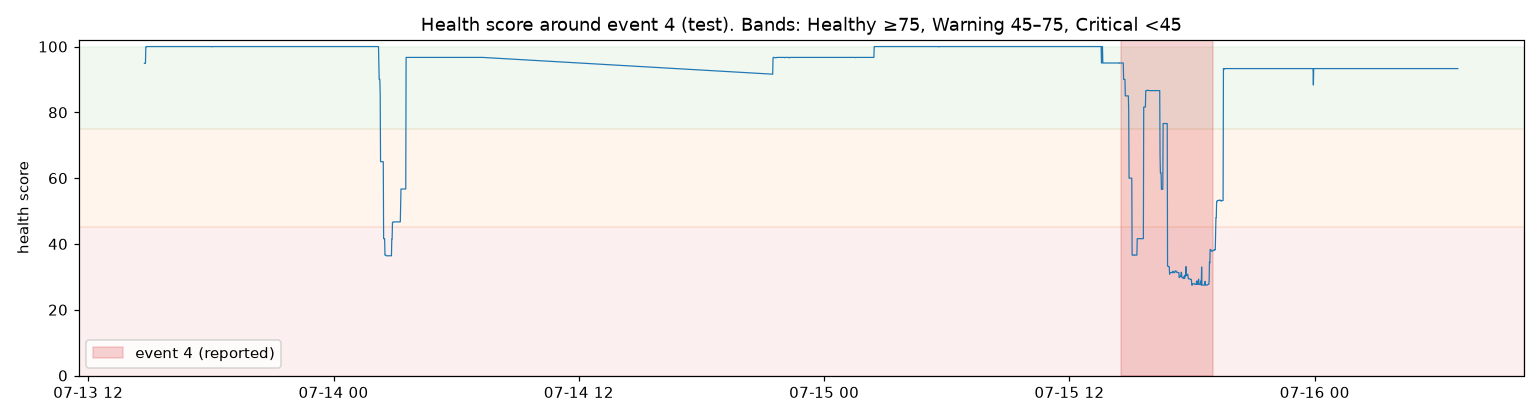

In [2]:
ml = pd.read_csv(R/'ml/test_results_detect.csv')[['model','pr_auc','roc_auc','recall','precision','false_alarms_per_day']]
an = pd.read_csv(R/'anomaly/anomaly_results.csv').query("set=='test'")[['detector','events_detected','false_alarms_per_day','minute_recall','minute_precision','pr_auc','roc_auc']]
dl = pd.read_csv(R/'dl/dl_seed_stability.csv')
display(Markdown('### Supervised (test, event 4)')); display(ml)
display(Markdown('### Anomaly detectors (test)')); display(an)
display(Markdown('### Deep learning across seeds (test)')); display(dl)
display(Markdown('### Health engine')); display(pd.read_csv(R/'health/health_status_by_truth.csv'))
show(F/'health/health_event4.png')